# LDA Deck-Level Model
**Modeling — Deck Granularity**

Implements LDA at slide-deck level following the CRISP-DM modeling phase.  
Library: `gensim`.  
Input: deck-level token lists produced by `src/utils.py`.  
Granularity: one document = one full slide deck (all pages of one lecture PDF aggregated).  
Corpus size: 9 documents (one per IDS lecture PDF).

> **Statistical constraint.** With 9 documents LDA operates below its typical minimum corpus
> requirements. Document-topic distributions carry high uncertainty; results should be
> interpreted as exploratory curriculum-level thematic profiles, not statistically stable
> topic models. See Section 6 for a full discussion.

**Structure:**
1. Setup & Data Loading
2. Corpus Preparation (dictionary + BoW)
3. Model Training
4. Topic Inspection
5. Evaluation (Coherence & Perplexity)
6. Model Summary & Review

## 1. Setup & Data Loading

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

_nb_dir = os.path.dirname(os.path.abspath('lda.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

warnings.filterwarnings('ignore')

# Plotting defaults
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'font.family'      : 'serif',
})
PALETTE = ['#2C5F8A', '#4C9BE8', '#A8C8E8', '#D9E8F5']

print('Libraries loaded.')

Libraries loaded.


In [2]:
from utils import load_corpus, tokenize_corpus, build_slide_deck_docs

# Load and Tokenize corpus
corpus = tokenize_corpus(load_corpus())

# Aggregate to deck level. One document per slide PDF.
docs = build_slide_deck_docs(corpus)

print(f'Documents (decks): {len(docs)}')
print(f'Token count — min: {docs.n_tokens.min()}, median: {docs.n_tokens.median():.0f}, max: {docs.n_tokens.max()}')
docs[['source_file', 'n_tokens']]

Documents (decks): 9
Token count — min: 58, median: 410, max: 669


,source_file,n_tokens
0,icd_1_v1_cleaned_v7.csv,488
1,icd_2_v1_cleaned_v7.csv,568
2,icd_3_v1_cleaned_v7.csv,669
3,icd_4_v1_cleaned_v7.csv,230
4,icd_5_v1_cleaned_v7.csv,58
5,icd_6_v1_cleaned_v7.csv,410
6,icd_7_v1_cleaned_v7.csv,523
7,icd_8_v1_cleaned_v7.csv,130
8,icd_9_v1_cleaned_v7.csv,270


## 2. Corpus Preparation

In [3]:
import gensim.corpora as corpora
from gensim.models import CoherenceModel

RANDOM_SEED = 42

texts = docs['tokens'].tolist()

# no_above relaxed to 0.9: with 9 docs the 0.8 ceiling is too aggressive (conservative thresholds)
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=2, no_above=0.9)
dictionary.compactify()

bow_corpus = [dictionary.doc2bow(text) for text in texts]

print(f'Vocabulary size (after filtering): {len(dictionary)}')
print(f'Corpus size: {len(bow_corpus)} documents')

Vocabulary size (after filtering): 335
Corpus size: 9 documents


In [4]:
from sklearn.model_selection import train_test_split

# With only 9 deck-level documents, a 90/10 split yields 0 test docs.
# Use 1 doc as holdout (leave-one-out): 8 train / 1 test.
train_docs, test_docs = train_test_split(docs, test_size=1, random_state=RANDOM_SEED)
train_docs = train_docs.reset_index(drop=True)
test_docs  = test_docs.reset_index(drop=True)

train_texts = train_docs['tokens'].tolist()
test_texts  = test_docs['tokens'].tolist()

# Rebuild dictionary and BoW corpus from train set only
dictionary = corpora.Dictionary(train_texts)
dictionary.filter_extremes(no_below=2, no_above=0.9)
dictionary.compactify()

bow_corpus = [dictionary.doc2bow(text) for text in train_texts]
test_bow   = [dictionary.doc2bow(text) for text in test_texts]


print(f'Train: {len(train_texts)} docs | Test: {len(test_texts)} docs')
print(f'Vocabulary size (after filtering): {len(dictionary)}')

Train: 8 docs | Test: 1 docs
Vocabulary size (after filtering): 318


## 3. Model Training

In [5]:
from gensim.models import LdaModel

# k=5: must stay below n_docs (9); 5 allows meaningful separation without overfitting
NUM_TOPICS  = 5
PASSES      = 30   # more passes to compensate for small corpus
ITERATIONS  = 500
ALPHA       = 0.1
ETA         = 0.01

lda = LdaModel(
    corpus          = bow_corpus,
    id2word         = dictionary,
    num_topics      = NUM_TOPICS,
    passes          = PASSES,
    iterations      = ITERATIONS,
    alpha           = ALPHA,
    eta             = ETA,
    random_state    = RANDOM_SEED,
    per_word_topics = True,
)

print(f'LDA trained: {NUM_TOPICS} topics, {PASSES} passes, seed={RANDOM_SEED}')

LDA trained: 5 topics, 30 passes, seed=42


## 4. Topic Inspection

In [6]:
# Top terms per topic

TOP_N = 10
for i, topic in lda.print_topics(num_topics=NUM_TOPICS, num_words=TOP_N):
    print(f'Topic {i:02d}: {topic}')

Topic 00: 0.029*"volume" + 0.029*"padrão" + 0.029*"tratamento" + 0.025*"europeu" + 0.025*"empresa" + 0.025*"modelo" + 0.021*"artificial" + 0.017*"população" + 0.017*"conteúdo" + 0.017*"pessoa"
Topic 01: 0.065*"variável" + 0.060*"valores" + 0.036*"atributo" + 0.029*"categórico" + 0.027*"classificação" + 0.024*"processo" + 0.021*"numérico" + 0.020*"target" + 0.020*"features" + 0.018*"aluno"
Topic 02: 0.085*"modelo" + 0.033*"resultado" + 0.029*"objetivo" + 0.028*"aprendizagem" + 0.024*"previsão" + 0.023*"conjunto" + 0.022*"variável" + 0.021*"treino" + 0.018*"avaliação" + 0.017*"decisão"
Topic 03: 0.035*"visualização" + 0.028*"conhecimento" + 0.026*"imagem" + 0.024*"texto" + 0.024*"análise" + 0.020*"projeto" + 0.017*"contexto" + 0.015*"processo" + 0.013*"conteúdo" + 0.013*"objetivo"
Topic 04: 0.061*"utilização" + 0.061*"visualização" + 0.061*"componente" + 0.061*"widget" + 0.061*"ligação" + 0.030*"utilizador" + 0.030*"input" + 0.030*"ferramenta" + 0.030*"mining" + 0.030*"automático"


In [7]:
from utils import generate_topic_labels_llm

TOPIC_LABELS = generate_topic_labels_llm(lda, NUM_TOPICS)

for idx, label in TOPIC_LABELS.items():
    print(f'T{idx:02d}: {label}')

T00: Data Ethics and Models
T01: Variáveis e atributos dados
T02: Modelagem supervisionada
T03: Visualização e análise de dados
T04: Visualização e interatividade Orange


In [8]:
# Topic summary table

rows = []
for i in range(NUM_TOPICS):
    terms = lda.show_topic(i, topn=TOP_N)
    top_words   = ', '.join(w for w, _ in terms)
    top_weights = [round(p, 3) for _, p in terms]
    rows.append({
        'Topic'     : f'T{i:02d}',
        'Label'     : TOPIC_LABELS[i],
        'Top 10 Terms': top_words,
        'Max weight': max(top_weights),
    })

topic_df = pd.DataFrame(rows).set_index('Topic')

topic_df.style \
    .set_caption('LDA Topics — Top 10 Terms per Topic (gensim, deck-level)') \
    .set_properties(**{'text-align': 'left'}) \
    .bar(subset=['Max weight'], color='#0156AB', vmin=0, vmax=0.15)

,Label,Top 10 Terms,Max weight
Topic,,,
T00,Data Ethics and Models,"volume, padrão, tratamento, europeu, empresa, modelo, artificial, população, conteúdo, pessoa",0.029000
T01,Variáveis e atributos dados,"variável, valores, atributo, categórico, classificação, processo, numérico, target, features, aluno",0.065000
T02,Modelagem supervisionada,"modelo, resultado, objetivo, aprendizagem, previsão, conjunto, variável, treino, avaliação, decisão",0.085000
T03,Visualização e análise de dados,"visualização, conhecimento, imagem, texto, análise, projeto, contexto, processo, conteúdo, objetivo",0.035000
T04,Visualização e interatividade Orange,"utilização, visualização, componente, widget, ligação, utilizador, input, ferramenta, mining, automático",0.061000


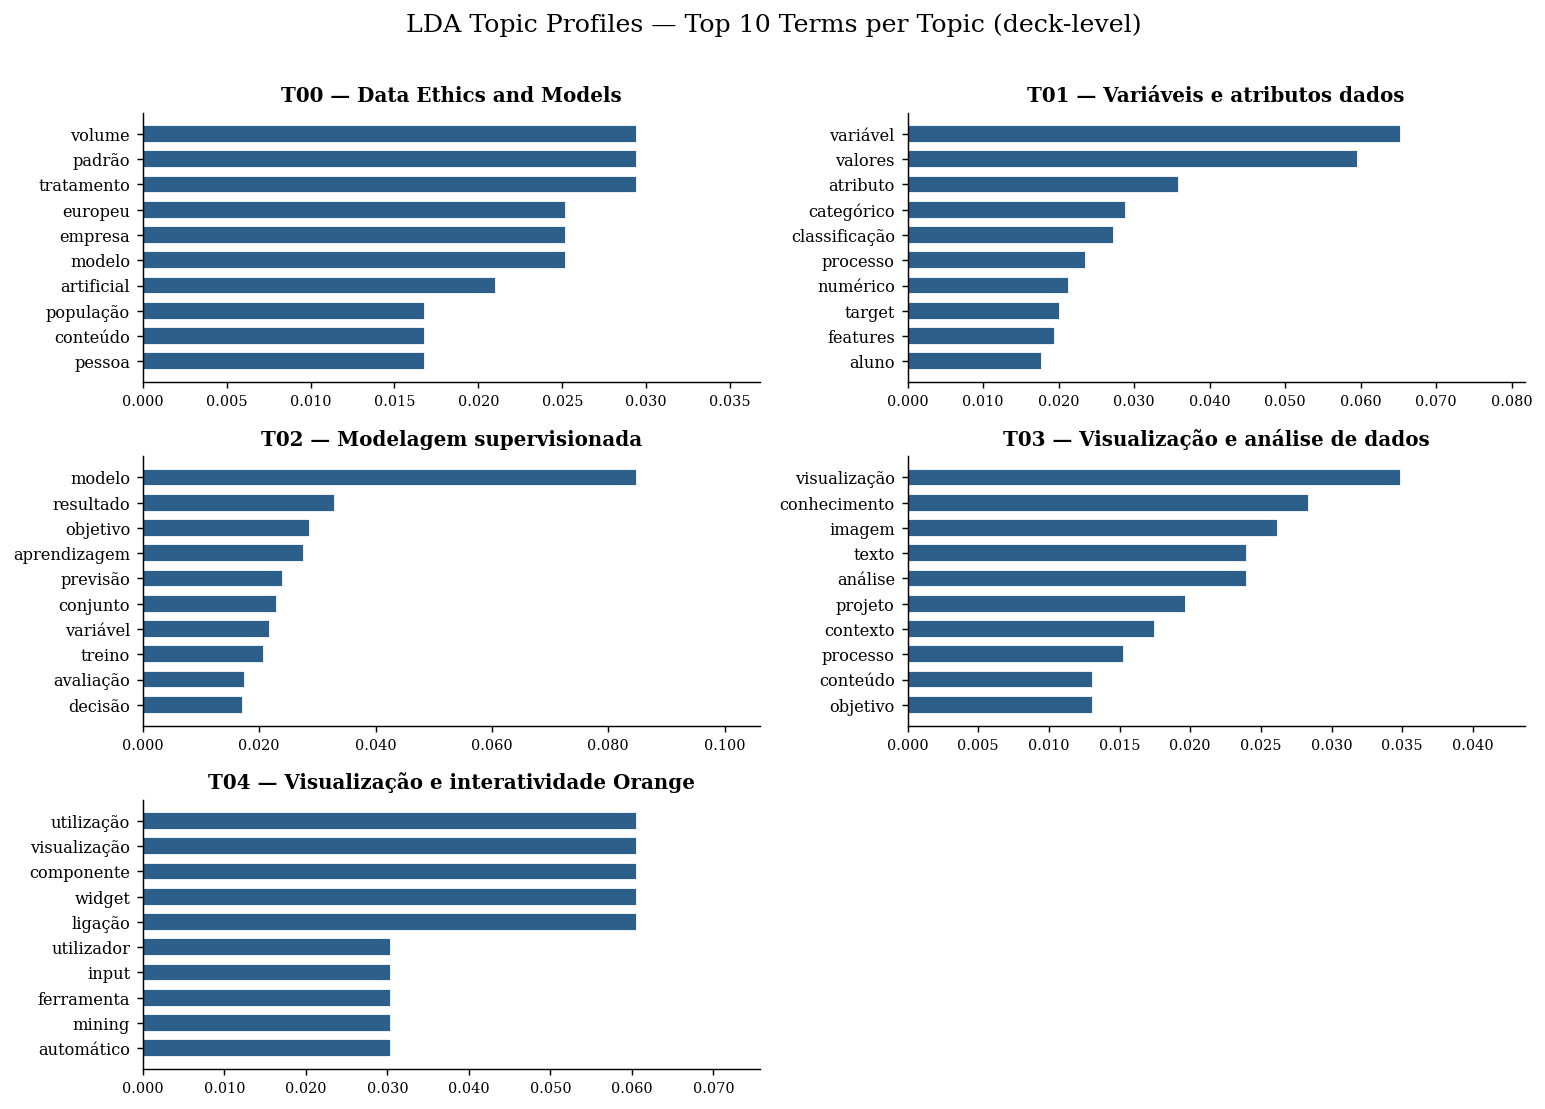

In [9]:
# Visualize topic profiles

TOP_VIS = 10
n_cols = 2
n_rows = (NUM_TOPICS + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 2.8))
axes = axes.flatten()

for i in range(NUM_TOPICS):
    terms   = lda.show_topic(i, topn=TOP_VIS)
    words   = [w for w, _ in terms][::-1]
    weights = [p for _, p in terms][::-1]

    ax = axes[i]
    ax.barh(words, weights, color=PALETTE[0], edgecolor='white', height=0.7)
    ax.set_title(f'T{i:02d} — {TOPIC_LABELS[i]}', fontsize=11, fontweight='bold')
    ax.set_xlim(0, max(weights) * 1.25)
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

for j in range(NUM_TOPICS, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('LDA Topic Profiles — Top 10 Terms per Topic (deck-level)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

               source_file  n_tokens  dominant_topic
0  icd_2_v1_cleaned_v7.csv       568               0
1  icd_6_v1_cleaned_v7.csv       410               1
2  icd_1_v1_cleaned_v7.csv       488               3
3  icd_9_v1_cleaned_v7.csv       270               3
4  icd_3_v1_cleaned_v7.csv       669               2
5  icd_5_v1_cleaned_v7.csv        58               4
6  icd_4_v1_cleaned_v7.csv       230               3
7  icd_7_v1_cleaned_v7.csv       523               1


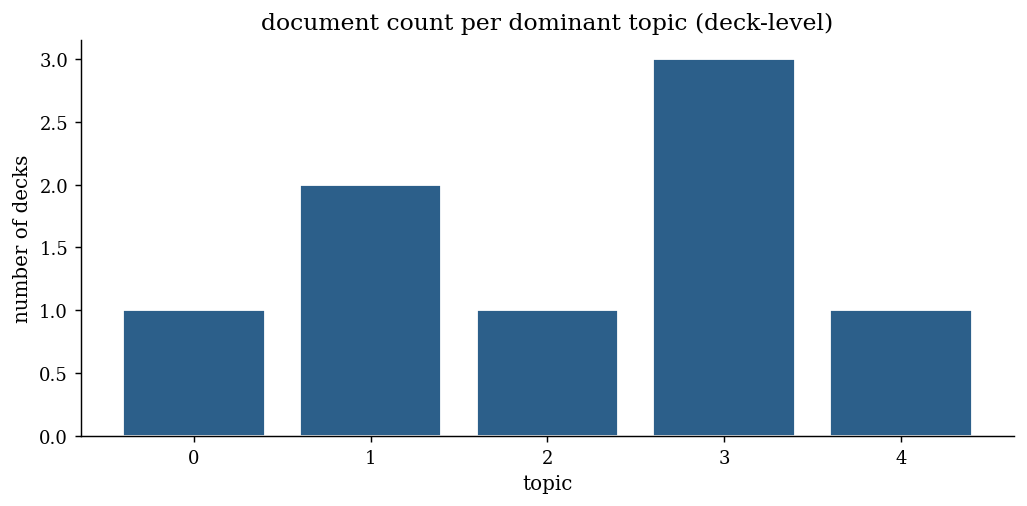

In [10]:
# Visualize document-topic distribution

train_docs_plot = train_docs.copy()
train_docs_plot['dominant_topic'] = [
    max(lda.get_document_topics(b), key=lambda x: x[1])[0] if lda.get_document_topics(b) else -1
    for b in bow_corpus
]

print(train_docs_plot[['source_file', 'n_tokens', 'dominant_topic']].to_string())

topic_dist = train_docs_plot['dominant_topic'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(topic_dist.index, topic_dist.values, color=PALETTE[0], edgecolor='white')
ax.set_xlabel('topic')
ax.set_ylabel('number of decks')
ax.set_title('document count per dominant topic (deck-level)')
ax.set_xticks(range(NUM_TOPICS))
plt.tight_layout()
plt.show()

## 5. Evaluation

In [11]:
from utils import compute_holdout_perplexity_gensim

# Coherence score (C_v) and perplexity for the current model
coherence_model = CoherenceModel(
    model=lda,
    texts=train_texts,
    dictionary=dictionary,
    coherence='c_v',
)
coherence_cv = coherence_model.get_coherence()
insample_perp = lda.log_perplexity(bow_corpus)
holdout = compute_holdout_perplexity_gensim(lda, test_bow)

print(f'Coherence (C_v)          : {coherence_cv:.4f}  (target > 0.50)')
print(f'Perplexity (in-sample)   : {float(np.exp(-insample_perp)):.4f}  [all train docs, biased]')
print(f'Perplexity (holdout)     : {holdout["raw_perplexity"]:.4f}  '
      f'[n_docs={holdout["n_docs"]}, n_words={holdout["n_words"]}]')

Coherence (C_v)          : 0.3747  (target > 0.50)
Perplexity (in-sample)   : 619.8764  [all train docs, biased]
Perplexity (holdout)     : 243.2802  [n_docs=1, n_words=59]


k= 2  C_v=0.3930


k= 3  C_v=0.4221


k= 4  C_v=0.4060


k= 5  C_v=0.3747


k= 6  C_v=0.3541


k= 7  C_v=0.4068


k= 8  C_v=0.4099


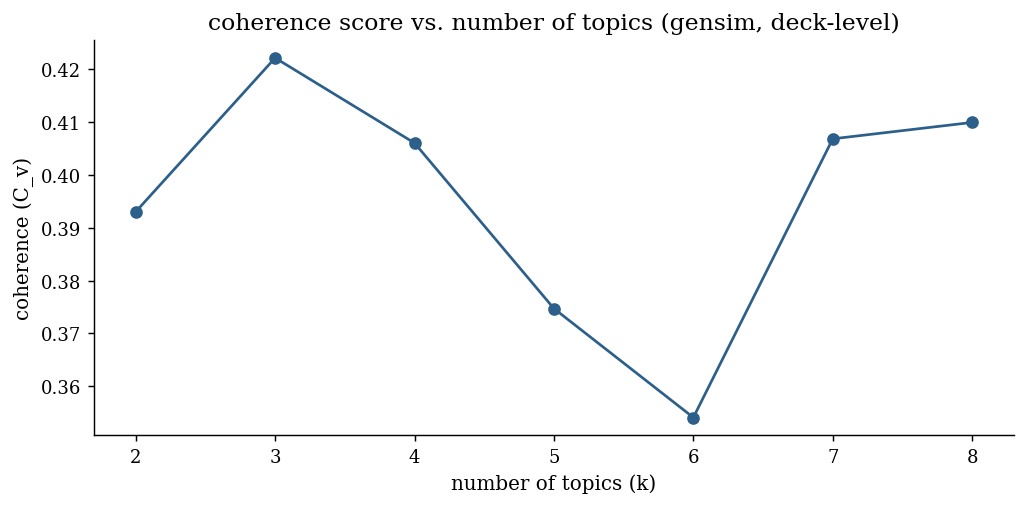


Best k=3  C_v=0.4221


In [12]:
# Coherence grid search over number of topics
# Helps to find the optimal K before committing to a final model and parameters.

TOPIC_RANGE = range(2, 9)

results = []
for k in TOPIC_RANGE:
    m = LdaModel(
        corpus       = bow_corpus,
        id2word      = dictionary,
        num_topics   = k,
        passes       = PASSES,
        iterations   = ITERATIONS,
        alpha        = ALPHA,
        eta          = ETA,
        random_state = RANDOM_SEED,
    )
    cv = CoherenceModel(model=m, texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
    results.append({'k': k, 'coherence_cv': round(cv, 4)})
    print(f'k={k:2d}  C_v={cv:.4f}')

results_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_df['k'], results_df['coherence_cv'], marker='o', color=PALETTE[0])
ax.set_xlabel('number of topics (k)')
ax.set_ylabel('coherence (C_v)')
ax.set_title('coherence score vs. number of topics (gensim, deck-level)')
ax.set_xticks(list(TOPIC_RANGE))
plt.tight_layout()
plt.show()

best = results_df.loc[results_df['coherence_cv'].idxmax()]
print(f'\nBest k={int(best.k)}  C_v={best.coherence_cv}')

## 6. Optimized K's

Original K: `NUM_TOPICS = 5`. Avoids trivial overfitting.
Re-train with **K=3** for a more conservative deck-level baseline in both libraries.

> **Note:** With only 9 documents, deck-level LDA is below the statistical sweet spot for topic models; results in this section are exploratory. Cross-library K cross-application is also skipped here because K=3 is already the chosen value for both deck-level notebooks.

In [13]:
# Multi-K sweep: train one model per K in K_GRID and store them in `models_by_k`.
# K_GRID covers the initial guess and each library's grid-search optimum.
K_GRID = [5, 3]
K_INITIAL = 5  
K_OWN_BEST = 3      

models_by_k = {K_INITIAL: lda}
for k in K_GRID:
    if k in models_by_k:
        continue
    m = LdaModel(
        corpus           = bow_corpus,
        id2word          = dictionary,
        num_topics       = k,
        passes           = PASSES,
        iterations       = ITERATIONS,
        alpha            = ALPHA,
        eta              = ETA,
        random_state     = RANDOM_SEED,
        per_word_topics  = True,
    )
    models_by_k[k] = m
    print(f'-- trained gensim LDA at k={k}, seed={RANDOM_SEED}')

lda_new = models_by_k[K_OWN_BEST]
NUM_TOPICS_NEW = K_OWN_BEST

TOP_N_NEW = 10
for k, m in models_by_k.items():
    print(f'\n=== k={k} top terms ===')
    for i in range(k):
        if hasattr(m, 'show_topic'):
            terms = m.show_topic(i, topn=TOP_N_NEW)
        else:
            terms = m.get_topic_words(i, top_n=TOP_N_NEW)
        term_str = ' + '.join(f'{p:.3f}*"{w}"' for w, p in terms)
        print(f'Topic {i:02d}: {term_str}')

TOPIC_LABELS_NEW = generate_topic_labels_llm(lda_new, NUM_TOPICS_NEW)
print()
for idx, label in TOPIC_LABELS_NEW.items():
    print(f'T{idx:02d}: {label}')


-- trained gensim LDA at k=3, seed=42

=== k=5 top terms ===
Topic 00: 0.029*"volume" + 0.029*"padrão" + 0.029*"tratamento" + 0.025*"europeu" + 0.025*"empresa" + 0.025*"modelo" + 0.021*"artificial" + 0.017*"população" + 0.017*"conteúdo" + 0.017*"pessoa"
Topic 01: 0.065*"variável" + 0.060*"valores" + 0.036*"atributo" + 0.029*"categórico" + 0.027*"classificação" + 0.024*"processo" + 0.021*"numérico" + 0.020*"target" + 0.020*"features" + 0.018*"aluno"
Topic 02: 0.085*"modelo" + 0.033*"resultado" + 0.029*"objetivo" + 0.028*"aprendizagem" + 0.024*"previsão" + 0.023*"conjunto" + 0.022*"variável" + 0.021*"treino" + 0.018*"avaliação" + 0.017*"decisão"
Topic 03: 0.035*"visualização" + 0.028*"conhecimento" + 0.026*"imagem" + 0.024*"texto" + 0.024*"análise" + 0.020*"projeto" + 0.017*"contexto" + 0.015*"processo" + 0.013*"conteúdo" + 0.013*"objetivo"
Topic 04: 0.061*"utilização" + 0.061*"visualização" + 0.061*"componente" + 0.061*"widget" + 0.061*"ligação" + 0.030*"utilizador" + 0.030*"input" + 0.


T00: Análise e Visualização Dados
T01: Características e atributos
T02: Modelagem supervisionada


## 7. Extended metrics

Complementary metrics are reported for **every** K in the sweep, each capturing a different aspect of model quality. Used together, they expose trade-offs that any single number would conceal.

- **C_v coherence (primary).** expecting the chosen K to score above 0.50 and to rank higher than alternatives, confirming that top words within each topic are semantically related.

- **U_mass coherence (secondary).** expecting its relative ranking across K values to agree with C_v, confirming that coherence differences are not artefacts of the external reference corpus.

- **Unified perplexity.** expecting perplexity to decrease as K increases, but values should be read alongside coherence since a lower perplexity does not guarantee interpretable topics.

- **Topic diversity (Dieng et al. 2020).** expecting diversity to remain high (close to 1), indicating that topics are not redundantly recycling the same high-frequency words.

- **Mean pairwise topic cosine similarity.** expecting low mean cosine similarity (well below 1), indicating that topic word-distributions are spread across distinct regions of the vocabulary.

- **Mean Shannon entropy of topic-word distributions.** expecting low normalised entropy, indicating that each topic concentrates probability mass on a small, coherent set of words rather than spreading it diffusely across the vocabulary.

The metrics for every K are persisted as JSON under `data/output/<notebook>_metrics.json` for the cross-notebook comparison in `lda_comparison_v2.ipynb`.

In [14]:
# Compute extended metrics for every K in K_GRID and persist as JSON.
import json, os
from utils import (
    compute_topic_diversity,
    compute_topic_cosine_similarity,
    compute_topic_entropy,
    unify_perplexity,
    compute_holdout_perplexity_gensim,
    OUTPUT_ROOT,
)

K_ROLE = {5: 'initial', 3: 'own_library_best'}

def _metrics(m, k):
    out = {}
    for coh_kind in ('c_v', 'u_mass'):
        out[f'coherence_{coh_kind}'] = float(
            CoherenceModel(model=m, texts=train_texts, dictionary=dictionary, coherence=coh_kind).get_coherence()
        )
    pp = unify_perplexity(m, bow_corpus=bow_corpus)
    out['raw_perplexity'] = pp['raw_perplexity']
    out['log_perplexity'] = pp['log_perplexity']
    ho = compute_holdout_perplexity_gensim(m, test_bow)
    out['holdout_raw_perplexity'] = ho['raw_perplexity']
    out['holdout_log_perplexity'] = ho['log_perplexity']
    out['holdout_n_docs']         = ho['n_docs']
    out['holdout_n_words']        = ho['n_words']
    vocab_size = m.num_vocabs if hasattr(m, 'num_vocabs') else len(m.id2word)
    out['topic_diversity_top25'] = compute_topic_diversity(
        m, k, n=25, vocab_size=vocab_size
    )
    cos = compute_topic_cosine_similarity(m, k)
    out['cosine_similarity_mean'] = cos['mean']
    out['cosine_similarity_max']  = cos['max']
    ent = compute_topic_entropy(m, k)
    out['shannon_entropy_mean']      = ent['mean']
    out['shannon_entropy_mean_norm'] = ent['mean_norm']
    out['topic_labels'] = {
        i: lbl for i, lbl in generate_topic_labels_llm(m, k).items()
    }
    out['k'] = int(k)
    out['role'] = K_ROLE.get(k, 'extra')
    return out

configs = [_metrics(m, k) for k, m in models_by_k.items()]

rows = []
for cfg_metrics in configs:
    rows.append({
        'role'                   : cfg_metrics['role'],
        'k'                      : cfg_metrics['k'],
        'coherence_c_v'          : cfg_metrics['coherence_c_v'],
        'coherence_u_mass'       : cfg_metrics['coherence_u_mass'],
        'raw_perplexity'         : cfg_metrics['raw_perplexity'],
        'holdout_raw_perplexity' : cfg_metrics['holdout_raw_perplexity'],
        'topic_diversity'        : cfg_metrics['topic_diversity_top25']['diversity'],
        'cosine_similarity'      : cfg_metrics['cosine_similarity_mean'],
        'shannon_entropy'        : cfg_metrics['shannon_entropy_mean'],
    })

metrics_df = pd.DataFrame(rows).set_index('role')
print('Extended metrics across K_GRID:')
display(metrics_df.style.format({
    'coherence_c_v': '{:.4f}', 'coherence_u_mass': '{:.4f}',
    'raw_perplexity': '{:.2f}', 'holdout_raw_perplexity': '{:.2f}',
    'topic_diversity': '{:.4f}', 'cosine_similarity': '{:.4f}',
    'shannon_entropy': '{:.4f}',
}))

by_role = {c['role']: c for c in configs}
metrics_payload = {
    'notebook': 'lda_v3',
    'library': 'gensim',
    'granularity': 'deck',
    'n_documents': int(len(docs)),
    'n_documents_train': len(train_texts),
    'n_documents_test':  len(test_texts),
    'vocab_size': int(list(models_by_k.values())[0].num_vocabs) if hasattr(list(models_by_k.values())[0], 'num_vocabs') else int(len(list(models_by_k.values())[0].id2word)),
    'random_seed': RANDOM_SEED,
    'k_grid': K_GRID,
    'configs': configs,
    'old_K': by_role['initial'],
    'new_K': by_role.get('own_library_best', by_role['initial']),
    'grid_search': results_df.to_dict(orient='records'),
}
json_path = os.path.join(OUTPUT_ROOT, 'lda_v3' + '_metrics.json')
os.makedirs(OUTPUT_ROOT, exist_ok=True)
with open(json_path, 'w') as f:
    json.dump(metrics_payload, f, indent=2)
print(f'Metrics written to: {json_path}')

Extended metrics across K_GRID:


,k,coherence_c_v,coherence_u_mass,raw_perplexity,holdout_raw_perplexity,topic_diversity,cosine_similarity,shannon_entropy
role,,,,,,,,
initial,5,0.3747,-0.6042,619.88,243.28,0.8160,0.2235,4.5509
own_library_best,3,0.4221,-0.8636,560.03,250.69,0.8267,0.2827,4.8410


Metrics written to: /Users/I749701/Developer/University/MIGThesis-126735/data/output/lda_v3_metrics.json
